<a href="https://colab.research.google.com/github/cbishop4/MSE7530/blob/main/ClassNotebooks/F2026/Lecture18_Ellipsometry_InClass_20261116.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MSE/CHE 7530/5995 - Lecture 11/16/26

## Part 0.5 - Imports

In [1]:
import matplotlib.pyplot as plt
import numpy as np

In [2]:
! pip install refnx
! pip install refellips

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 8.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 32.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [refnx]
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for refellips: filename=refellips-0.0.6-py3-none-any.whl size=318157 sha256=206f341984d3c89a994daa605cf5beb018f37e15618bc8b8c436c95a5e406e4b
  Stored in directory: /root/.cache/pip/wheels/91/a1/7c/03363a9b6e4f79a8831033240fdf69d5a4197140ca12c810be
Successfully built refellips


In [3]:
import refellips as se

In [4]:
import sys
import os
from os.path import join as pjoin
import numpy as np
import matplotlib.pyplot as plt
import scipy

import refnx
from refnx.analysis import CurveFitter
from refnx.reflect import Slab

import refellips
from refellips.dataSE import DataSE, open_EP4file
from refellips.reflect_modelSE import ReflectModelSE
from refellips.objectiveSE import ObjectiveSE
from refellips.dispersion import RI, Cauchy, load_material

In [5]:
! git clone https://github.com/cbishop4/MSE7530/

Cloning into 'MSE7530'...
remote: Enumerating objects: 1117, done.
remote: Counting objects: 100% (252/252), done.
remote: Compressing objects: 100% (189/189), done.
remote: Total 1117 (delta 181), reused 62 (delta 62), pack-reused 865 (from 1)
Receiving objects: 100% (1117/1117), 204.36 MiB | 24.26 MiB/s, done.
Resolving deltas: 100% (459/459), done.


## Help for Questions (Not graded - for your own information)

### Question 1 Help.

Question 1 will require you to use the beginning functions in refellips. This is designed so that you can learn a little more about what the code is fundamentally doing.

Recall that the formula for the MSE is $MSE = \frac{1}{n}\sum_{i=1}^{n}{(Data - Model)^2} $

https://www.spiedigitallibrary.org/journals/optical-engineering/volume-48/issue-12/124603/Refractive-index-control-in-bicomponent-polymer-films-for-integrated-thermo/10.1117/1.3275452.short

## Questions (Only work below this line will be graded)

### Question 1. Using refellips, model the $\Psi$ and $\Delta$ values for a film of PNIPAM on Silicon with a 2 nm native oxide layer. (25 points)

For the first question, you will be modeling data for a polymer on Si/SiO2. Here, we will illustrate the principles with Polystyrene. Polystyrene exists in the "materials" folder in the refellips code. (https://github.com/refnx/refellips/tree/main/refellips/materials)

In [6]:
# load up all the materials you will use
air = load_material('air')
silicon = load_material('silicon')
sio2 = load_material('silica')
PS = load_material('polystyrene')

In [7]:
# make a model structure, specifying the thickness of each layer
structure = air | PS(3000.) | sio2(25.) | silicon
# turn the structure into a model
model = ReflectModelSE(structure)

For this question, rather than proceeding all the way to making an objective function, we are just going to simulate the psi and delta that would be generated by performing ellipsometry on this model film. We need to specify which wavelengths and incident angles we will simulate the data at; you want this to be the same as your data. For the sake of argument, I will use only 70 degree incident angles. The format must be a 2D array, with the first column wavelengths and the second column Angles of incidence.

In [8]:
msmt_wl = np.linspace(250., 1000., 50)
AOIs = np.ones(50) * 70.
msmts = np.column_stack((msmt_wl, AOIs))
msmts

array([[ 250.        ,   70.        ],
       [ 265.30612245,   70.        ],
       [ 280.6122449 ,   70.        ],
       [ 295.91836735,   70.        ],
       [ 311.2244898 ,   70.        ],
       [ 326.53061224,   70.        ],
       [ 341.83673469,   70.        ],
       [ 357.14285714,   70.        ],
       [ 372.44897959,   70.        ],
       [ 387.75510204,   70.        ],
       [ 403.06122449,   70.        ],
       [ 418.36734694,   70.        ],
       [ 433.67346939,   70.        ],
       [ 448.97959184,   70.        ],
       [ 464.28571429,   70.        ],
       [ 479.59183673,   70.        ],
       [ 494.89795918,   70.        ],
       [ 510.20408163,   70.        ],
       [ 525.51020408,   70.        ],
       [ 540.81632653,   70.        ],
       [ 556.12244898,   70.        ],
       [ 571.42857143,   70.        ],
       [ 586.73469388,   70.        ],
       [ 602.04081633,   70.        ],
       [ 617.34693878,   70.        ],
       [ 632.65306122,   

We can find the simulated psi and delta just by calling the model with the specified measurement conditions.

In [9]:
simulated = model(msmts)
simulated

(array([41.71531097, 36.57083035, 34.24342842, 36.85966413, 46.21892856,
        76.14482276, 47.19284424, 37.61710096, 31.23513623, 23.79779691,
        19.5907202 , 20.78040339, 24.81472638, 29.38548841, 34.48859888,
        41.40781126, 52.40026818, 70.1001715 , 78.3928087 , 61.04985509,
        48.68026275, 40.91375757, 35.75061063, 31.85469798, 28.60125819,
        25.69426054, 23.00898092, 20.46152439, 18.0335678 , 15.74772629,
        13.65863576, 11.86171638, 10.46811469,  9.60260515,  9.34178452,
         9.66086236, 10.43020653, 11.49069306, 12.74218458, 14.1003305 ,
        15.47889117, 16.84881166, 18.17380208, 19.46439244, 20.71097791,
        21.91757964, 23.08034197, 24.21158435, 25.31697371, 26.38402792]),
 array([ 76.39936536, 118.11971691, 200.45154084, 257.58138916,
        267.17586053, 167.82218869,  82.94768793,  85.29096478,
        107.79051749, 140.93568059, 182.54668794, 226.13904864,
        254.37495197, 271.13307196, 280.80197096, 285.76635083,
        288.

In [10]:
psis = simulated[0]; deltas = simulated[1]

Text(0.5, 0.98, 'Simulated Ellipsometric Angles for 300 nm Polystyrene')

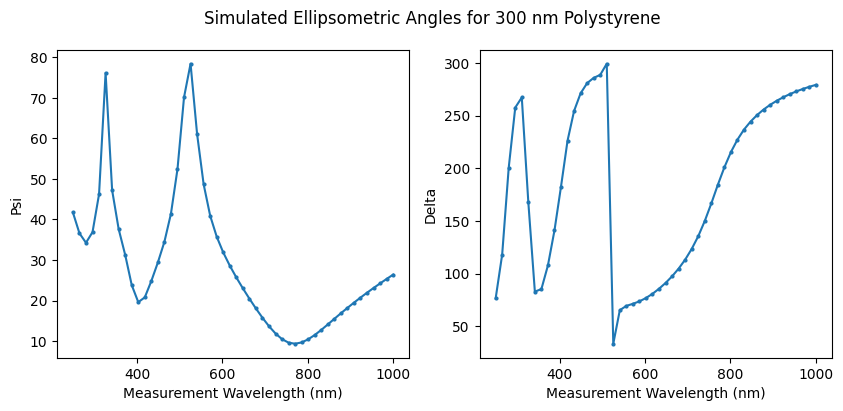

In [11]:
fig, ax = plt.subplots(1,2,figsize=(10,4))
ax[0].plot(msmt_wl, psis,'-o',markersize=2)
ax[1].plot(msmt_wl, deltas,'-o',markersize=2)
for a in ax:
  a.set_xlabel('Measurement Wavelength (nm)')
ax[0].set_ylabel('Psi'); ax[1].set_ylabel('Delta')
plt.suptitle('Simulated Ellipsometric Angles for 300 nm Polystyrene')

#### Part A.  Make 2 graphs - one of $\Psi$ vs. wavelength, and one of $\Delta$ vs. wavelength, from 50 to 600 nm-thick in increments of 50 nm at $70°$ angle of incidence.

Start with specifying an array with values from 50 to 600 in spacings of 50 nm.

In [ ]:
# your code here

From the code earlier, you will need to generate a new structure for each thickness. I have reproduced the above code with a note on which needs to be modified.

In [ ]:
# make a model structure, specifying the thickness of each layer
structure = air | PS(3000.) | sio2(25.) | silicon # MODIFY THIS LINE
# turn the structure into a model
model = ReflectModelSE(structure)

In [ ]:
msmt_wl = np.linspace(250., 1000., 50)
AOIs = np.ones(50) * 70.
msmts = np.column_stack((msmt_wl, AOIs))

In [ ]:
simulated = model(msmts) #DISCUSS; what have we done here?

As a class, we'll come together and discuss exactly what we've done here.

Your turn: write a loop to perform this for each thickness and make a plot as above, but it will have multiple lines.

In [ ]:
# your code here

#### Part B. For each of the curves that you manually generated in Part A, calculate the mean-squared error (MSE) between your curve and the experimental data contained in the given file, 'PNIPAM_q1.txt'

In [12]:
dataPNI = '/content/MSE7530/sampledata/PNIPAM_q1.txt'

As a class we will discuss: What is the approach we will take here? We'll go through the pseudo-code on the board together.

In [ ]:
# your code here

In [ ]:
# your code here

### Determine the percentage of Polycarbonate (PC) in a PMMA-PC blend. (We will go through the approach for this on the board, and I have reproduced some helpful information below).

In [ ]:
datafile = '/content/MSE7530/sampledata/sim_ellipsometry.txt'

### Question 2 Help.
In this question, you will use the full functionality of RefEllips to determine the optical constants of a polymer and link it to a physical meaning. For full functionality of refellips, see the demo that we used in class, "Ellipsometry.ipynb".

An important difference in this question is that you will not **only** be varying thickness, but you will also need to fit for an A value. Do not fit the B parameter; assume it to be fixed at 0.003, and C fixed at 0.

In [ ]:
si = load_material('silicon')
air = load_material('air')
sio2 = load_material('silica')
fitpol = Cauchy(A=1.7, B = 0.003)

Below is the notation for how you set the option to vary the A parameter.

In [ ]:
fitlayer = fitpol(5000.) # needs some thickness to initialize
fitlayer.thick.setp(value=9000., vary=True, bounds=(0.,10000.))
fitlayer.ri.A.setp(value=1.7, vary=True,bounds=(1.0,2.0))

After this, make the structure and proceed as usual. This table will give you information to help make the final determination of PC content. Use only the A parameters.

Cauchy Parameters for PMMA and PC

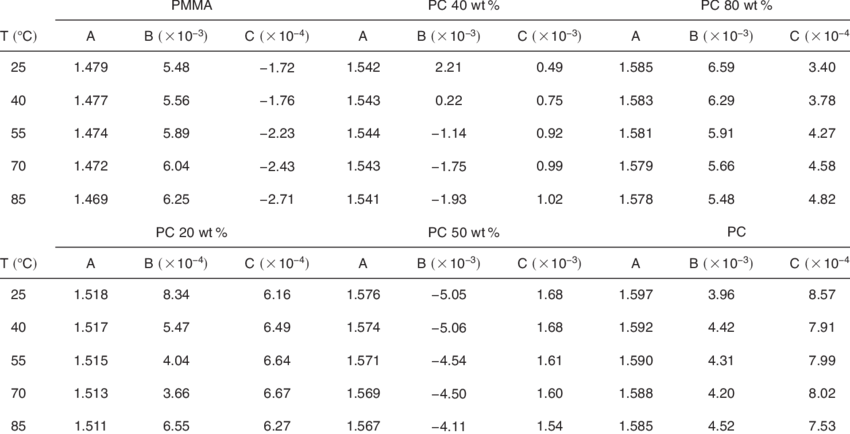

#### Bonus Question: Examine the values in the table. Why should you not trust this data? (The A parameters are fine)